In [15]:
import pandas as pd
import numpy as np
import re
import os
import umap
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import requests
import gzip
from tqdm import tqdm
import pandas as pd
from thefuzz import process, fuzz

In [2]:
PLOT_CONFIG = {
    "figure_default": (12, 6),
    "figure_large": (14, 8),
    "figure_medium": (10, 6),
    "figure_scatter": (10, 8),
    "bar_color_green": "#4CAF50",
    "palette_yellow_red": "YlOrRd",
    "palette_viridis": "viridis",
    "rotation": 45,
}

def create_vbar_plot(data: pd.DataFrame, x_col: str, y_col: str,
                    title: str, x_label: str, y_label: str,
                    figsize: tuple = None, palette: str = None,
                    rotate_x: bool = True) -> plt.Figure:
    """Reusable vertical bar plot."""
    fig, ax = plt.subplots(figsize=figsize or PLOT_CONFIG["figure_default"])

    sns.barplot(
        x=x_col,
        y=y_col,
        data=data,
        hue=x_col,
        palette=palette or PLOT_CONFIG["palette_yellow_red"],
        legend=False
    )

    if rotate_x:
        ax.set_xticks(ax.get_xticks())
        ax.set_xticklabels(ax.get_xticklabels(), rotation=PLOT_CONFIG["rotation"], ha="right")

    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    plt.tight_layout()
    return fig

def create_hbar_plot(data: pd.DataFrame, x_col: str, y_col: str,
                    title: str, x_label: str, y_label: str,
                    figsize: tuple = None, color: str = None) -> plt.Figure:
    """Reusable horizontal bar plot."""
    fig, ax = plt.subplots(figsize=figsize or PLOT_CONFIG["figure_default"])

    bars = ax.barh(
        data[y_col],
        data[x_col],
        color=color or PLOT_CONFIG["bar_color_green"],
        edgecolor="white",
        linewidth=0.5
    )

    ax.set_xlabel(x_label, fontsize=12)
    ax.set_ylabel(y_label, fontsize=12)
    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.invert_yaxis()
    plt.tight_layout()
    return fig

def create_histogram_with_kde(data: pd.DataFrame, column: str,
                             title: str, x_label: str, y_label: str,
                             color: str = "green", figsize: tuple = None) -> plt.Figure:
    """Reusable histogram with KDE overlay."""
    fig, ax = plt.subplots(figsize=figsize or PLOT_CONFIG["figure_medium"])

    sns.histplot(
        data=data,
        x=column,
        kde=True,
        color=color,
        stat='density',
        alpha=0.8
    )

    sns.despine()
    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    plt.tight_layout()
    return fig

def create_scatter_clustering(X: np.ndarray, labels: np.ndarray,
                             var_explained: tuple, title: str = None,
                             figsize: tuple = None) -> plt.Figure:
    """Reusable PCA/UMAP scatter plot for clustering."""
    fig, ax = plt.subplots(figsize=figsize or PLOT_CONFIG["figure_scatter"])

    scatter = ax.scatter(
        X[:, 0], X[:, 1],
        c=labels,
        cmap=PLOT_CONFIG["palette_viridis"],
        alpha=0.6,
        s=100,
        edgecolors='black'
    )

    ax.set_xlabel(f'PC1 ({var_explained[0]:.1%})')
    ax.set_ylabel(f'PC2 ({var_explained[1]:.1%})')
    ax.set_title(title or 'Clustering Visualization', fontsize=14, fontweight="bold")
    ax.grid(True, alpha=0.3)

    cbar = plt.colorbar(scatter, label='Cluster')
    cbar.set_label('Cluster', fontsize=12)

    plt.tight_layout()
    return fig

def create_dendrogram(linkage_matrix: np.ndarray, title: str = "Hierarchical Clustering Dendrogram",
                     cut_threshold: float = None, figsize: tuple = None) -> plt.Figure:
    """Reusable dendrogram plot."""
    fig, ax = plt.subplots(figsize=figsize or PLOT_CONFIG["figure_large"])

    dendrogram(
        linkage_matrix,
        truncate_mode='lastp',
        p=50,
        leaf_rotation=90,
        leaf_font_size=10
    )

    if cut_threshold:
        ax.axhline(y=cut_threshold, color='r', linestyle='--',
                   label=f'Cut threshold={cut_threshold}')
        ax.legend()

    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_xlabel('Drug Classes')
    ax.set_ylabel('Distance')
    plt.tight_layout()
    return fig

def create_heatmap_comparison(data: pd.DataFrame, title: str,
                             cmap: str = "RdBu_r") -> plt.Figure:
    """Reusable heatmap for comparing two groups."""
    fig, ax = plt.subplots(figsize=(8, 6))

    sns.heatmap(
        data,
        annot=True,
        fmt='.2f',
        cmap=cmap,
        cbar_kws={'label': 'Average Frequency'}
    )

    ax.set_title(title, fontsize=14, fontweight="bold")
    plt.tight_layout()
    return fig

def compare_clustering_methods(X_original: np.ndarray, X_reduced: np.ndarray,
                               k_range: range, random_state: int = 42) -> dict:
    """Compare silhouette scores with and without dimensionality reduction."""
    results = {}
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    for i, (X_input, name, marker, color) in enumerate([
        (X_original, 'Without PCA', 'o', 'blue'),
        (X_reduced, 'With PCA', 's', 'purple')
    ]):
        scores = []
        for k in k_range:
            km = KMeans(n_clusters=k, random_state=random_state, n_init=10).fit(X_input)
            sil = silhouette_score(X_input, km.labels_)
            scores.append(sil)

        optimal_k = list(k_range)[scores.index(max(scores))]
        results[name] = {'scores': scores, 'optimal_k': optimal_k}

        axes[i].plot(k_range, scores, marker=marker, linewidth=2, color=color)
        axes[i].set_xlabel('Number of Clusters (k)')
        axes[i].set_ylabel('Silhouette Score')
        axes[i].set_title(name, fontsize=13)
        axes[i].axvline(optimal_k, color='red', linestyle='--',
                       label=f'Optimal k={optimal_k}')
        axes[i].legend()
        axes[i].grid(True, alpha=0.3)

    plt.tight_layout()
    return results, fig

In [3]:
# =============================================================================
# SECTION 1: DATA LOADING AND PREPROCESSING
# =============================================================================

# Load CSV and remove unnamed columns
df = pd.read_csv("drugs_side_effects_drugs_com.csv", index_col=False)
df.drop(df.columns[df.columns.str.contains('unnamed', case=False)], axis=1, inplace=True)

# Remove non-essential columns
df = df.drop(columns=["drug_link", "medical_condition_url"])

# Convert numeric columns, handle comma separators, and coercion errors
df["no_of_reviews"] = pd.to_numeric(
    df["no_of_reviews"].astype(str).str.replace(",", "").str.strip(),
    errors="coerce"
)
df["rating"] = pd.to_numeric(
    df["rating"].astype(str).str.replace(",", "").str.strip(),
    errors="coerce"
)

In [4]:
# =============================================================================
# SECTION 2: TEXT CLEANING PIPELINE DEFINITIONS
# =============================================================================

# Length constraints: filters to remove fragmented or overly verbose side effects
LENGTH_CONSTRAINTS = {
    "max_effect_length": 45,
    "min_effect_length": 6,
    "max_words_per_effect": 6,
}

CODE_CONFIG_PATTERNS = [
    r'[{}<>]',
    r'["\']',
    r'[/:_]',
    r'[()]',
    r'&&|\|\||!=?|=+',
    r'\b(function\s*\(|\.prototype\b|console\.)\b',
    r'\b(getElement|querySelector|setAttribute|addEventListener)\b',
    r'\b(var\s+\w+\s*=|=\s*"\w+)\b',
    r'px$|\d+px',
    r'[a-f0-9]{8,}',
    r'\b(atob\(|[a-z0-9]{6,})\b',
    r'\b(if|else|return|try|catch)\b',
    r'\b(https[:]?)\b'
]

INGREDIENT_PATTERNS = [
    r'\b(sodium|chloride|acid|lactose)\b',
    r'\b(mg|g|ml|%|tablet|capsule|injection|antibiotic[s]?)\b',
    r'\b(syrup|solution|gel|cream|ointment|advil|bi|dose[s]?|vapo)\b',
]

BOILERPLATE_PATTERNS = [
    r'\b(information|storage|protect|children|vitamin[s]?|prescription[s]?|it|if)\b',
    r'\b(devices|available|flavoring|smith|kline|water|reserved|share|html|mailto|lazy|weak|child|parent[s]?|abb)\b',
    r'\b(alert[s]?|newsletter[s]?|update[s]?|other[s]?)\b',
    r'\b(doctor[s]?)\b',
    r'\b(nurse[s]?)\b',
    r'\be\d+\b',
    r'\b(used|effectiveness|include|infection[s]?|vaccination[s]?|afterward|bacteria|animal[s]?|caution|assist)',
    r'\b(pharmacist[s]?)\b',
    r'\b(do not|don\'t).*freeze\b',
    r'\bprotect.*from.*(light|moisture|heat)\b',
    r'\b(common side effects of|side effects such as)\b',
    r'\b(may|occur|contact|this|help|using|medicine[s]?|notice|professional[s]?|healthcare|also|get|call|seek|check|signs|which|threatening)\b'
]

JUNK_KEYWORDS = [
    "of", "bothersome", "light", "count",
    "modal", "group", "inset", "media", "table", "query", "lower",
    "multi", "propa", "lin", "kwik", "log", "nitro", "covid", "death",
    "chlor"
]

VALID_SHORT_WORDS = {
    "rash",
    "pain",
    "itch",
    "fever",
    "cough"
}

EXPLICIT_BLACKLIST = {
    "along with its needed effects", "unwanted effects", "needed effects",
    "people who", "in rare cases", "rare cases", "sometimes death",
    "does not go away", "especially on face", "in those who are debilitated",
    "green in color", "in some cases", "aqua gem", "at night", "not at all",
    "keep all drugs in safe place", "mark clear", "in back", "more often",
    "store in dry place"
}
PROTECTED_PHRASES = {
    "little or no urination": "urination decreased",
    "watery or bloody": "watery stool",
    "bloody or tarry": "blood in stool",
    "loss of appetite": "appetite loss",
    "ringing in your ears": "tinnitus",
}

SYNONYM_MAP = {
    "trouble breathing": "difficulty breathing",
    "shortness of breath": "difficulty breathing",
    "breathing difficulty": "difficulty breathing",
    "difficult breathing": "difficulty breathing",
    "short of breath": "difficulty breathing",
    "yellowing of skin": "jaundice",
    "yellowing skin": "jaundice",
    "swelling of face": "facial swelling",
    "headaches": "headache",
    "muscle aches": "muscle pain",
    "muscle ache": "muscle pain",
    "diarrhea that is watery stool": "watery stool",
    "12 deficiency": "B12 deficiency",
    "pins": "pins and needles",
    "if you feel impulsive": "impulsiveness",
    "of liver problems like dark urine": "dark urine",
    "leading to kidney failure": "kidney failure",
    "codeine can slow breathing": "slow breathing",
    "vagina): burning": "vaginal burning",
    "agitated": "agitation",
    "cloudy urine fever with": "cloudy urine",
    "as: agitation": "agitation",
    'pruned" appearance of skin': "pruned appearance of skin",
    "flaking": "skin flaking",
    "anxious": "anxiety",
    "any other changes in hearing": "changes in hearing",
    "cold symptoms such as stuffy nose": "stuffy nose",
    "cold symptoms such as runny": "runny nose",
    "excited (especially in children": "excitable",
    "excited": "excitable",
    'hangover" feeling after night': "hangover feeling after night",
    "concentration": "concentration problems",
    "unusual sense of well": "unusual sense of wellbeing",
    "flushing (warmth": "hot flushes",
    "flushing (sudden warmth": "hot flushes",
    "heat flushing": "hot flushes",
    "hyperactive (mentally": "hyperactive",
    "have thoughts about suicide": "suicidal thoughts",
    "thoughts of suicide": "suicidal thoughts",
    "blood in stool stools": "blood in stool",
    "hive": "hives",
    "stomach pain (upper right side": "stomach pain",
    "feelings of low self": "feelings of low self esteem",
    "esteem": "feelings of low self esteem",
    "breath that smells like fruit": "fruity breath odor",
    "more hungry": "increased hunger",
    "hostile": "hostility",
    "runny": "runny nose",
    "not hungry": "appetite loss",
    "mood": "mood changes",
    "side effects such as dry mouth": "dry mouth",
    "feeling anxious": "anxiety",
    "throwing up": "vomiting",
    "like passing out": "lightheadedness",
    "sleep problems ( insomnia": "insomnia",
    "like symptoms": "flu like symptoms",
    "feeling light": "lightheadedness",
    "tremor": "tremors",
    "trouble concentrating": "concentration problems",
    "tired": "tiredness",
    "like you might pass out" : "dizziness",
    "headed feeling": "lightheadedness",
    "fast heartbeats":"fast heartbeat",
    "clay": "clay coloured stool"
}

INGREDIENT_REGEX = re.compile("|".join(INGREDIENT_PATTERNS), re.I)
BOILERPLATE_REGEX = re.compile("|".join(BOILERPLATE_PATTERNS), re.I)
JUNK_REGEX = re.compile(r"\b(?:" + "|".join(JUNK_KEYWORDS) + r")\b", re.I)
CODE_REGEX = re.compile("|".join(CODE_CONFIG_PATTERNS), re.I)
ALPHANUMERIC_MIX_PATTERN = re.compile(
    r'^(?=.*[a-zA-Z])(?=.*[0-9])[a-zA-Z0-9]+$',
    re.I
)

In [24]:
SIDE_EFFECT_CATEGORIES = {
    'DERMATOLOGICAL': [
        r'\brash\b', r'\bskin[rain]? ?', r'\bhives\b', r'\bulcer\b', r'\bsore\b',
        r'\bblister\b', r'\bwarmth\b', r'\bflushing\b', r'\bpale\b', r'\byellowing\b',
        r'\bsweat\b', r'\bfacial ?swelling\b', r'\bskin ?peeling\b', r'\bpruritus\b',
        r'\burticaria\b', r'\bdermatitis\b'
    ],

    'CARDIOVASCULAR': [
        r'\bheart ?beat\b', r'\bpalpitat\b', r'\btachycardia\b', r'\bbradycardia\b',
        r'\bchest ?pain\b', r'\bangina\b', r'\bhypertension\b', r'\bhypotension\b',
        r'\barrhythmia\b', r'\bpulse\b', r'\bblood ?pressure\b'
    ],

    'GASTROINTESTINAL': [
        r'\bvomit\b', r'\bdiarrhea\b', r'\bnausea\b', r'\bconstipat\b',
        r'\bstomatitis\b', r'\bgastrointestinal\b', r'\bdyspepsia\b',
        r'\babdominal ?pain\b', r'\bbelly ?pain\b', r'\bnauseous\b',
        r'\bdysphagia\b', r'\bgastritis\b'
    ],

    'NEUROLOGICAL': [
        r'\bheadache\b', r'\bdizzy\b', r'\btremor\b', r'\bsyncope\b',
        r'\bconvulsion\b', r'\bseizure\b', r'\bparaesthesia\b', r'\bnumb\b',
        r'\btwitch\b', r'\bspasm\b', r'\bvertigo\b', r'\bataxia\b',
        r'\bconfusion\b', r'\bmemory\b'
    ],

    'PSYCHIATRIC': [
        r'\banxiety\b', r'\bdepress\b', r'\binsomnia\b', r'\bmood\b',
        r'\bagitat\b', r'\bparanoid\b', r'\bpsychosi\b', r'\bhallucin\b',
        r'\bsuicidal\b', r'\bimpulsiv\b', r'\bemotional\b', r'\bsleep\b',
        r'\bdream\b', r'\bnervous\b', r'\bracing ?thought'
    ],

    'GENITO-URINARY': [
        r'\burinat\b', r'\bkidney\b', r'\bbladder\b', r'\bprotein ?in ?urine\b',
        r'\bhematuria\b', r'\bdysuria\b', r'\bfrequency\b', r'\bretention\b',
        r'\bvaginal\b', r'\bmenstrual\b', r'\bordect\b', r'\bedema\b'
    ],

    'SYSTEMIC/GENERAL': [
        r'\bfever\b', r'\bchill\b', r'\bfatigue\b', r'\bw[eo]akness\b',
        r'\bmalaise\b', r'\bpain\b', r'\bdiscomfort\b', r'\binfection\b',
        r'\binflammation\b', r'\bredness\b', r'\bswelling\b', r'\bflu-?like\b'
    ],

    'RESPIRATORY': [
        r'\bdyspnea\b', r'\bcough\b', r'\bwheeze\b', r'\bbronchospasm\b',
        r'\brales\b', r'\bapnoea\b', r'\bnasal\b', r'\bsinusi\b',
        r'\bpharyngiti\b', r'\blaryngeal\b'
    ],

    'HEPATIC': [
        r'\bliver\b', r'\bhepati\b', r'\bcholestasi\b', r'\bhepatotox\b',
        r'\bjoundice\b', r'\btransaminase\b', r'\benzyme\b'
    ],

    'HEMATOLOGIC': [
        r'\bleukopenia\b', r'\bneutropenia\b', r'\banemia\b', r'\bthrombocytopenia\b',
        r'\bleukocyte\b', r'\bwhite ?blood\b', r'\bblood disorder\b',
        r'\bbruise\b', r'\bhemorrhage\b', r'\bblood ?loss\b'
    ],

    'MUSCULOSKELETAL': [
        r'\barthralgia\b', r'\bmyalgia\b', r'\bstiffness\b', r'\bspasm\b',
        r'\bmuscle ?pain\b', r'\bjoint ?pain\b', r'\bback ?pain\b',
        r'\bskeletal\b', r'\bcramp\b', r'\btrouble ?walk\b'
    ],

    'OCULAR': [
        r'\bv[ision]?tion\b', r'\bblurred\b', r'\beye ?pain\b',
        r'\bconjunctiv\b', r'\bdry ?eye\b', r'\bphotophobia\b'
    ],

    'METABOLIC': [
        r'\bsugar\b', r'\bdiabete\b', r'\bhyperglycem\b', r'\bhypoglycem\b',
        r'\bglucose\b', r'\bweight ?gain\b', r'\bweight ?loss\b',
        r'\bappetite\b', r'\bdehydration\b', r'\belectrolyte\b'
    ]
}

MEDDRA_SYSTEM_ORGAN_CLASSES = [
    "Infections and infestations",
    "Neoplasms benign, malignant and unspecified",
    "Blood and lymphatic system disorders",
    "Immune system disorders",
    "Endocrine disorders",
    "Metabolism and nutrition disorders",
    "Psychiatric disorders",
    "Nervous system disorders",
    "Eye disorders",
    "Ear and labyrinth disorders",
    "Cardiac disorders",
    "Vascular disorders",
    "Respiratory, thoracic and mediastinal disorders",
    "Gastrointestinal disorders",
    "Hepatobiliary disorders",
    "Skin and subcutaneous tissue disorders",
    "Musculoskeletal and connective tissue disorders",
    "Renal and urinary disorders",
    "Reproductive system and breast disorders",
    "Congenital, familial and genetic disorders",
    "General disorders and administration site conditions",
    "Investigations",
    "Injury, poisoning and procedural complications",
    "Surgical and medical procedures",
    "Social circumstances",
    "Product issues",
    "Unclassified"
]

In [25]:
def strip_boilerplate(txt: str) -> str:
    txt = str(txt)
    txt = re.sub(r"([a-z])([A-Z])", r"\1. \2", txt)

    sentences = re.split(r"(?<=[.!])\s+", txt)
    kept = []

    for s in sentences:
        sl = s.lower()

        allergy_templ = "hives" in sl and "breathing" in sl
        resp_templ = any(k in sl for k in [
            "unusual hoarseness",
            "tightness in the chest or throat",
            "signs of an allergic reaction",
        ])

        boiler = BOILERPLATE_REGEX.search(sl) or any(p in sl for p in EXPLICIT_BLACKLIST)

        if not (allergy_templ or resp_templ or boiler):
            kept.append(s)

    return " ".join(kept)

def is_junk(effect: str) -> bool:
    if not effect or not isinstance(effect, str):
        return True

    effect_clean = effect.lower().strip()

    if INGREDIENT_REGEX.search(effect_clean):
        return True

    if BOILERPLATE_REGEX.search(effect_clean):
        return True

    if JUNK_REGEX.search(effect_clean):
        return True

    if ALPHANUMERIC_MIX_PATTERN.search(effect_clean):
        return True

    if effect_clean in EXPLICIT_BLACKLIST:
        return True

    if re.search(r'\b\d+\b', effect_clean):
        return True
    if re.search(r'\d+[°]', effect_clean):
        return True

    if '°' in effect_clean:
        return True

    BODY_PARTS = {
        "eye", "eyes", "hand", "hands", "foot", "feet", "leg", "legs",
        "arm", "arms", "finger", "fingers", "toe", "toes", "lip", "lips",
        "tongue", "mouth", "nose", "shoulder", "shoulders", "chest",
        "back", "stomach", "head", "neck", "ear", "ears", "thigh", "thighs",
        "knee", "knees", "wrist", "wrists", "ankle", "ankles", "hip", "hips",
        "waist", "belly", "breast", "breasts", "face", "bone", "throat",
        "body", "fingernail beds", "fingernail", "fingernails"
    }

    if effect_clean in BODY_PARTS:
        return True

    if len(effect_clean) < LENGTH_CONSTRAINTS["min_effect_length"]:
        if effect_clean in VALID_SHORT_WORDS:
            return False
        return True

    if len(effect_clean) > LENGTH_CONSTRAINTS["max_effect_length"]:
        return True

    if len(effect_clean.split()) > LENGTH_CONSTRAINTS["max_words_per_effect"]:
        return True

    return False

def is_code_artifact(text: str) -> bool:
    if not text or not isinstance(text, str):
        return True

    if CODE_REGEX.search(text.lower()):
        return True

    if re.match(r'^[a-z0-9]{6,}$', text):
        return True

    if len(text) <= 3 and re.match(r'^[a-z0-9]+$', text):
        return True

    return False

def apply_protected_phrases(text: str) -> str:
    for original, canonical in PROTECTED_PHRASES.items():
        text = re.sub(
            re.escape(original), canonical, str(text), flags=re.I
        )
    return text

def apply_synonyms(effects_series: pd.Series) -> pd.Series:
    return effects_series.replace(SYNONYM_MAP)

def normalise_side_effect_text(text: str) -> str:
    if not isinstance(text, str):
        return ""
    text = text.lower().strip()
    text = re.sub(r"^[^\w\s]+|[^\w\s]+$", "", text)
    text = re.sub(r"\s+", " ", text).strip()

    text = re.sub(
        r"^(get|call|seek|check|signs|of|your|a|an|that|is|are|feeling|having)"
        r"\s+", "", text, flags=re.IGNORECASE
    )
    text = re.sub(
        r"^((or|and|with|including|such))\s+", "", text, flags=re.IGNORECASE
    )

    text = re.sub(r"\b(your|the|a|an)\b", "", text, flags=re.IGNORECASE)

    text = re.sub(r"\s+", " ", text).strip()

    return text

def extract_side_effects(df_raw: pd.DataFrame) -> pd.DataFrame:
    df = df_raw.copy()

    df["side_effects_clean"] = df["side_effects"].apply(
        lambda x: apply_protected_phrases(x)
    )

    df["side_effects_clean"] = df["side_effects_clean"].apply(strip_boilerplate)

    df = df.assign(
        side_effects=df["side_effects_clean"].str.split(
            r"[-,;.\n]\s*|\s+(?:or|and)\s+"
        )
    ).explode("side_effects").reset_index(drop=True)

    df["side_effects"] = df["side_effects"].apply(normalise_side_effect_text)
    df["side_effects"] = apply_synonyms(df["side_effects"])

    df = df[df["side_effects"].apply(lambda x: not is_junk(x))].copy()
    df = df[df["side_effects"].apply(lambda x: not is_code_artifact(x))].copy()

    df = df.drop_duplicates(subset=["drug_name", "side_effects"]).reset_index(drop=True)

    return df

def categorize_side_effect(effect: str, category_patterns: dict = SIDE_EFFECT_CATEGORIES) -> str:
    effect_lower = effect.lower()
    matches = {}

    for category, patterns in category_patterns.items():
        for pattern in patterns:
            if re.search(pattern, effect_lower, re.IGNORECASE):
                if category not in matches:
                    matches[category] = 0
                matches[category] += 1

    if matches:
        return max(matches, key=matches.get)
    else:
        return 'Unclassified'

class MeddraClassifier:
    def __init__(self, socs=None, custom_categories=None, threshold=75):
        self.socs = socs or MEDDRA_SYSTEM_ORGAN_CLASSES
        self.custom_categories = custom_categories
        self.threshold = threshold

        print(f"MedDRA Classifier initialized")
        print(f"    Standard SOCs: {len(self.socs)-1}")
        print(f"    Custom categories: {len(custom_categories) if custom_categories else 0}")
        print(f"    Confidence threshold: {threshold}")

    def classify_single(self, effect: str) -> dict:
        result = {
            'effect': effect,
            'meddra_soc': 'UNCATEGORIZED',
            'confidence': 0,
            'method': 'none'
        }

        match, score = process.extractOne(
            effect,
            self.socs,
            scorer=fuzz.WRatio
        )

        result['confidence'] = score

        if score >= self.threshold:
            result['meddra_soc'] = match
            result['method'] = 'meddra_direct'
        elif score >= self.threshold - 25:
            result['meddra_soc'] = match
            result['method'] = 'meddra_low_confidence'
        else:
            if self.custom_categories:
                custom_cat = categorize_side_effect(effect, self.custom_categories)
                result['meddra_soc'] = custom_cat
                result['method'] = 'custom_fallback'

            result['confidence'] = score

        return result

    def classify_all(self, effects_series: pd.Series, progress: bool = True) -> pd.DataFrame:
        results = []

        iterator = tqdm(effects_series, desc="Classifying", disable=not progress) if progress else effects_series

        for effect in iterator:
            result = self.classify_single(effect)
            results.append(result)

        return pd.DataFrame(results)

    def get_coverage_stats(self, classification_df: pd.DataFrame) -> dict:
        total = len(classification_df)

        stats = {
            'total': total,
            'meddra_direct': len(classification_df[classification_df['method'] == 'meddra_direct']),
            'meddra_low_confidence': len(classification_df[classification_df['method'] == 'meddra_low_confidence']),
            'custom_fallback': len(classification_df[classification_df['method'] == 'custom_fallback']),
            'uncategorized': len(classification_df[classification_df['meddra_soc'] == 'UNCATEGORIZED'])
        }

        stats['meddra_total'] = stats['meddra_direct'] + stats['meddra_low_confidence']
        stats['meddra_pct'] = (stats['meddra_total'] / total) * 100
        stats['custom_pct'] = (stats['custom_fallback'] / total) * 100

        return stats

    def print_summary(self, classification_df: pd.DataFrame):
        stats = self.get_coverage_stats(classification_df)

        print("MEDDRA CLASSIFICATION SUMMARY")
        print(f"\nTotal side effects:          {stats['total']:,}")
        print(f"MedDRA direct match:         {stats['meddra_direct']:,} ({stats['meddra_direct']/stats['total']*100:.1f}%)")
        print(f"MedDRA low confidence:       {stats['meddra_low_confidence']:,} ({stats['meddra_low_confidence']/stats['total']*100:.1f}%)")
        print(f"Custom category fallback:    {stats['custom_fallback']:,} ({stats['custom_pct']:.1f}%)")
        print(f"Still uncategorized:         {stats['uncategorized']:,} ({stats['uncategorized']/stats['total']*100:.1f}%)")
        print(f"Total MedDRA coverage:       {stats['meddra_pct']:.1f}%")

def run_meddra_classification(long_se, confidence_threshold=75):
    classifier = MeddraClassifier(
        socs=MEDDRA_SYSTEM_ORGAN_CLASSES,
        custom_categories=SIDE_EFFECT_CATEGORIES,
        threshold=confidence_threshold
    )
    classification_df = classifier.classify_all(long_se['side_effects'])
    classifier.print_summary(classification_df)
    long_se = pd.concat([long_se.reset_index(drop=True), classification_df], axis=1)

    print("\nClassification complete!")
    print(f"    Added columns: meddra_soc, confidence, method")

    return long_se, classifier, classification_df

In [7]:
long_se = extract_side_effects(df)

In [8]:
print(f"Total unique side effects represented: {len(long_se)}")
print(f'Unique drugs represented: {long_se["drug_name"].nunique()}')
print(f'Unique medical conditions treated: {long_se["medical_condition"].nunique()}')
print(f"\nTop 10 most common side effects:")
top_side_effects = long_se["side_effects"].value_counts().head(10)
print(top_side_effects)
print(f"\nFirst 15 cleaned side effects:")
print(long_se["side_effects"].head(10))

Total unique side effects represented: 459
Unique drugs represented: 207
Unique medical conditions treated: 35

Top 10 most common side effects:
side_effects
fever                     76
chest pain                56
not able to pass urine    55
skin rash                 34
dark urine                26
mouth sores               19
joint pain                18
pain                      16
very bad belly pain       14
skin sores                13
Name: count, dtype: int64

First 15 cleaned side effects:
0     skin rash
1         fever
2    joint pain
3         cough
4          rash
5     skin rash
6         fever
7    joint pain
8     pale skin
9     skin rash
Name: side_effects, dtype: str


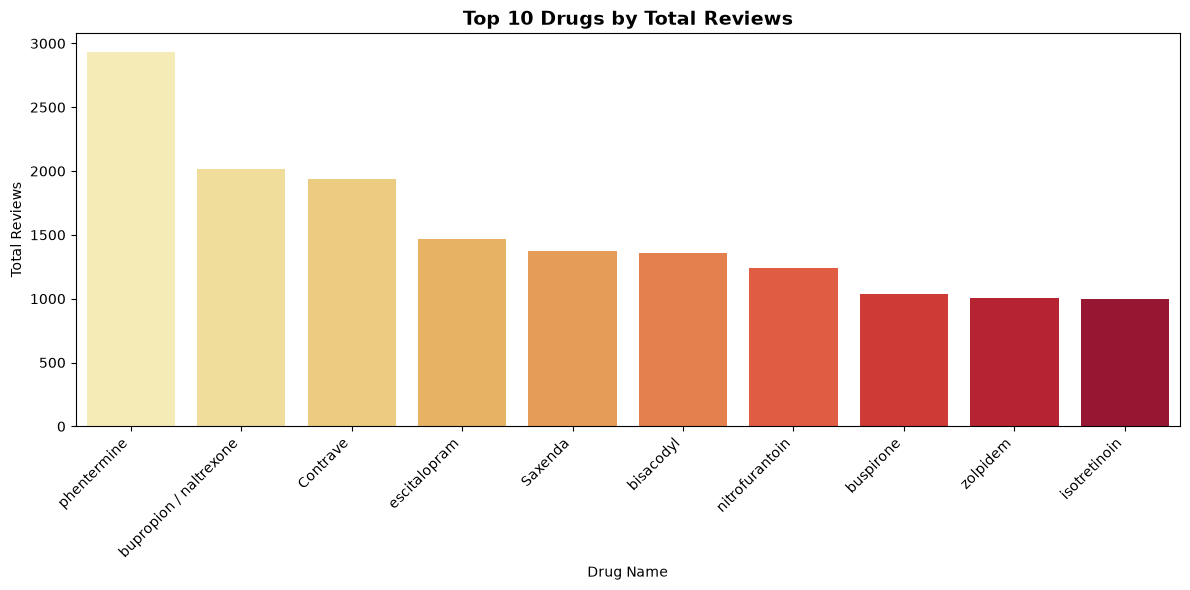

In [9]:
## Exploratory Data Analysis: Visualisations
# Top Reviewed Drugs
drug_reviews = df.groupby("drug_name")["no_of_reviews"].sum().reset_index()
top_reviewed_drugs = drug_reviews.nlargest(10, "no_of_reviews")
fig = create_vbar_plot(
    top_reviewed_drugs,
    x_col="drug_name",
    y_col="no_of_reviews",
    title="Top 10 Drugs by Total Reviews",
    x_label="Drug Name",
    y_label="Total Reviews"
)
plt.show()

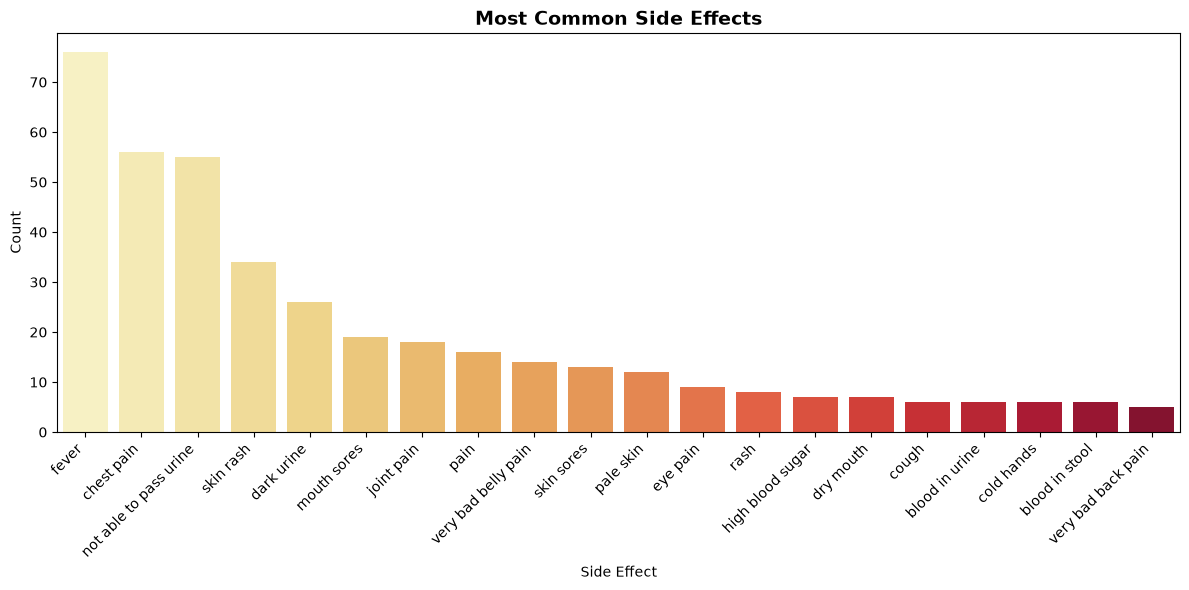

In [10]:
# Most common side effects
top_side_effects = (
    long_se["side_effects"]
    .value_counts()
    .head(20)
    .reset_index(name="count")
)
top_side_effects.columns = ["side_effects", "count"]

fig = create_vbar_plot(
    top_side_effects,
    x_col="side_effects",
    y_col="count",
    title="Most Common Side Effects",
    x_label="Side Effect",
    y_label="Count"
)
plt.show()

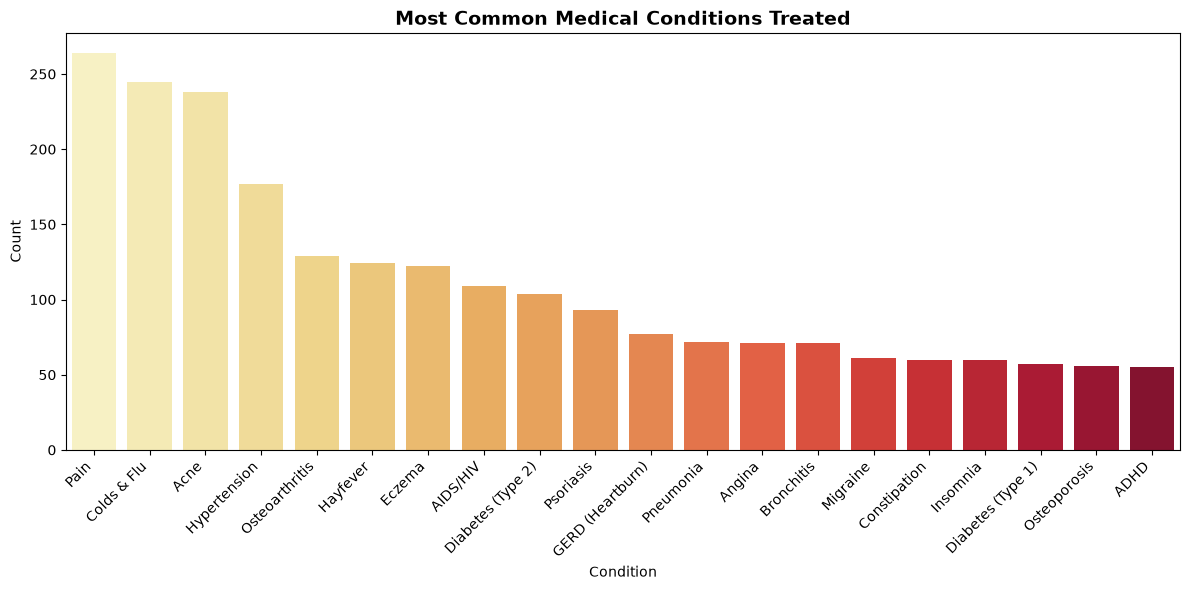

In [11]:
# Top medical conditions with drugs
top_conditions = (
    df["medical_condition"]
    .value_counts()
    .head(20)
    .reset_index(name="count")
)
top_conditions.columns = ["medical_condition", "count"]

fig = create_vbar_plot(
    top_conditions,
    x_col="medical_condition",
    y_col="count",
    title="Most Common Medical Conditions Treated",
    x_label="Condition",
    y_label="Count"
)
plt.show()

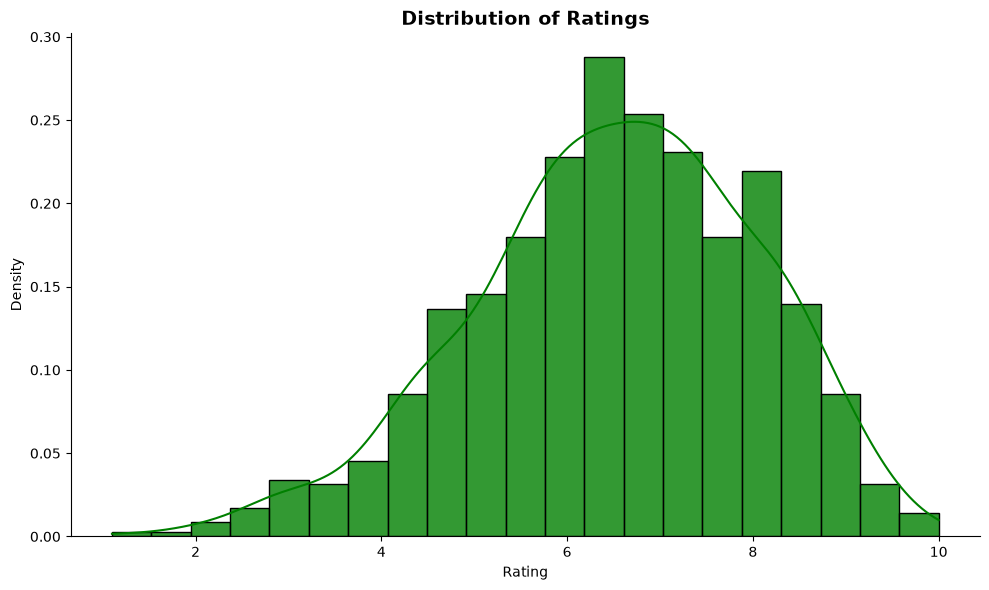

In [12]:
# Distribution of ratings
filtered_df = df[df["no_of_reviews"] > 10]

fig = create_histogram_with_kde(
    filtered_df,
    column='rating',
    title="Distribution of Ratings",
    x_label='Rating',
    y_label='Density',
    color='green'
)
plt.show()

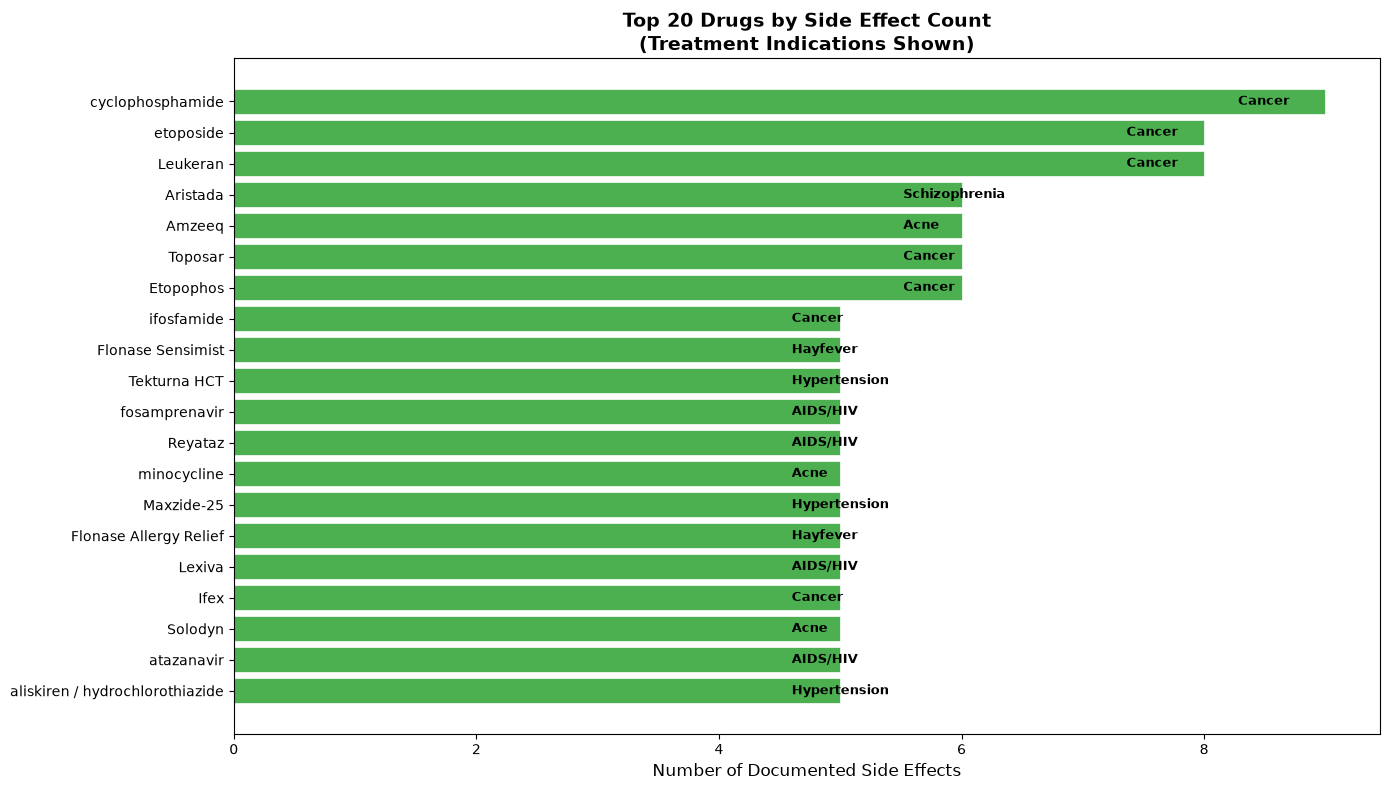

In [13]:
def create_drug_side_effect_plot(plot_data: pd.DataFrame,
                                  figsize: tuple = None) -> plt.Figure:
    """Horizontal bar plot with treatment condition annotations."""
    fig, ax = plt.subplots(figsize=figsize or PLOT_CONFIG["figure_large"])

    bars = ax.barh(
        plot_data["drug_name"],
        plot_data["num_side_effects"],
        color=PLOT_CONFIG["bar_color_green"],
        edgecolor="white",
        linewidth=0.5
    )

    for idx, row in plot_data.iterrows():
        cond_text = row["primary_condition"][:30] + "..." if len(row["primary_condition"]) > 30 else row["primary_condition"]
        ax.text(
            row["num_side_effects"] * 0.92, idx,
            cond_text,
            va="center",
            fontsize=9,
            color="black",
            fontweight="bold"
        )

    ax.set_xlabel("Number of Documented Side Effects", fontsize=12)
    ax.set_title("Top 20 Drugs by Side Effect Count\n(Treatment Indications Shown)",
                 fontsize=14, fontweight="bold")
    ax.invert_yaxis()
    plt.tight_layout()
    return fig

side_effect_counts = (
    long_se.groupby("drug_name")["side_effects"]
    .count()
    .sort_values(ascending=False)
    .head(20)
    .reset_index(name="num_side_effects")
)

drug_conditions = (
    long_se.groupby("drug_name")["medical_condition"]
    .agg(lambda x: x.value_counts().index[0] if len(x) > 0 else "Unknown")
    .reset_index()
    .rename(columns={"medical_condition": "primary_condition"})
)

plot_data = side_effect_counts.merge(drug_conditions, on="drug_name")

fig = create_drug_side_effect_plot(plot_data)
plt.show(fig)

In [28]:
long_se_classified, classifier, classification_df = run_meddra_classification(
        long_se=long_se,
        confidence_threshold=75
    )
print(long_se_classified['meddra_soc'].head(10))

MedDRA Classifier initialized
    Standard SOCs: 26
    Custom categories: 13
    Confidence threshold: 75


Classifying: 100%|██████████| 459/459 [00:00<00:00, 7209.87it/s]

MEDDRA CLASSIFICATION SUMMARY

Total side effects:          459
MedDRA direct match:         95 (20.7%)
MedDRA low confidence:       183 (39.9%)
Custom category fallback:    181 (39.4%)
Still uncategorized:         0 (0.0%)
Total MedDRA coverage:       60.6%

Classification complete!
    Added columns: meddra_soc, confidence, method
0    Skin and subcutaneous tissue disorders
1                          SYSTEMIC/GENERAL
2               Infections and infestations
3                               RESPIRATORY
4                   Hepatobiliary disorders
5    Skin and subcutaneous tissue disorders
6                          SYSTEMIC/GENERAL
7               Infections and infestations
8    Skin and subcutaneous tissue disorders
9    Skin and subcutaneous tissue disorders
Name: meddra_soc, dtype: str


In [36]:
long_se_classified['main_drug_class'] = long_se_classified['drug_classes'].str.split(',').str[0].str.strip()
soc_counts = pd.crosstab(long_se_classified['main_drug_class'], long_se_classified['meddra_soc'])
print(f"Drug classes: {soc_counts.shape[0]}")
print(f"MedDRA SOCs: {soc_counts.shape[1]}")
soc_columns = [col for col in soc_counts.columns if col != 'Unclassified']
soc_matrix = soc_counts[soc_columns].copy()
soc_matrix_pct = soc_matrix.div(soc_matrix.sum(axis=1), axis=0) * 100

Drug classes: 64
MedDRA SOCs: 20
